<a href="https://colab.research.google.com/github/haroldcolmenaresrodriguez-cyber/Proyecto-Integrador-/blob/main/PROYECTO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install --upgrade yfinance -q

import yfinance as yf
import pandas as pd
from google.colab import files

print("Descargando series 2019-2021...")

start_date = "2019-01-01"
end_date = "2021-12-31"

# Usamos EC (Ecopetrol ADR en NYSE) como proxy bursátil colombiana líquida y activa
# BZ=F (Brent Crude) y COP=X (USD/COP)
tickers_map = {
    'EC': 'Acciones_Colombia_USD',   # Proxy bursátil colombiana (USD en NYSE)
    'BZ=F': 'Brent_USD_Cierre',       # Petróleo Brent (USD/barril)
    'COP=X': 'USD_COP_Cierre'         # Tasa de cambio (COP por USD)
}

series_dict = {}

for ticker, nombre in tickers_map.items():
    try:
        # auto_adjust=False para evitar el warning de FutureWarning
        df = yf.download(ticker, start=start_date, end=end_date, progress=False, auto_adjust=False)

        # Extraer columna de cierre de forma limpia
        if isinstance(df.columns, pd.MultiIndex):
            col_cierre = df['Close'].iloc[:, 0]
        else:
            col_cierre = df['Close']

        series_dict[nombre] = col_cierre
        print(f"-> {ticker} ({nombre}): {len(col_cierre)} observaciones descargadas.")
    except Exception as e:
        print(f"Error con {ticker}: {e}")

# Unir las series en un solo DataFrame
df_precios = pd.DataFrame(series_dict)
df_precios.index = pd.to_datetime(df_precios.index)

# Armonizar calendario común y descartar festivos de fin de año
df_clean = df_precios.dropna().copy()
df_clean = df_clean[~((df_clean.index.month == 1) & (df_clean.index.day == 1))]
df_clean = df_clean[~((df_clean.index.month == 12) & (df_clean.index.day == 25))]

print(f"\nTotal observaciones comunes: {len(df_clean)}")

if len(df_clean) > 0:
    filename = "base_precios_depurada_2019_2021_LosEndeudados.csv"
    df_clean.to_csv(filename, index_label="Fecha")
    print(f"Archivo exportado: {filename}\n")
    print("Primeras filas:")
    print(df_clean.head())
    print("\nÚltimas filas:")
    print(df_clean.tail())

    # Descarga directa a tu computador
    files.download(filename)
else:
    print("La base sigue vacía. Revisa la conectividad.")

Descargando series 2019-2021...
-> EC (Acciones_Colombia_USD): 756 observaciones descargadas.
-> BZ=F (Brent_USD_Cierre): 756 observaciones descargadas.
-> COP=X (USD_COP_Cierre): 782 observaciones descargadas.

Total observaciones comunes: 755
Archivo exportado: base_precios_depurada_2019_2021_LosEndeudados.csv

Primeras filas:
            Acciones_Colombia_USD  Brent_USD_Cierre  USD_COP_Cierre
Date                                                               
2019-01-02              16.459999         54.910000          3245.0
2019-01-03              16.500000         55.950001          3235.0
2019-01-04              17.510000         57.060001          3243.0
2019-01-07              17.770000         57.330002          3191.0
2019-01-08              18.280001         58.720001          3179.0

Últimas filas:
            Acciones_Colombia_USD  Brent_USD_Cierre  USD_COP_Cierre
Date                                                               
2021-12-23                  13.13        

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

# Fuerza la descarga del archivo generado
files.download("base_precios_depurada_2019_2021_LosEndeudados.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

# Cargar la base descargada
df = pd.read_csv("base_precios_depurada_2019_2021_LosEndeudados.csv", index_col="Fecha", parse_dates=True)

print("--- VERIFICACIÓN TÉCNICA DEL ACTIVO ---")
col_activo = [c for c in df.columns if 'Acciones' in c or 'EC' in c][0]

print(f"Columna evaluada: {col_activo}")
print(f"Precio Mínimo: {df[col_activo].min():.2f} USD (Choque Pandemia 2020)")
print(f"Precio Máximo: {df[col_activo].max():.2f} USD (Nivel Pre-pandemia 2019)")
print(f"Precio Promedio: {df[col_activo].mean():.2f} USD")
print(f"\nObservaciones totales verificadas: {len(df)}")

--- VERIFICACIÓN TÉCNICA DEL ACTIVO ---
Columna evaluada: Acciones_Colombia_USD
Precio Mínimo: 6.68 USD (Choque Pandemia 2020)
Precio Máximo: 23.03 USD (Nivel Pre-pandemia 2019)
Precio Promedio: 14.79 USD

Observaciones totales verificadas: 755


In [ ]:
import pandas as pd

# Cargar la base previa
df = pd.read_csv("base_precios_depurada_2019_2021_LosEndeudados.csv")

# 1. Asegurar formato de fecha ISO (YYYY-MM-DD)
df['Fecha'] = pd.to_datetime(df['Fecha']).dt.strftime('%Y-%m-%d')

# 2. Renombrar columna bursátil
if 'Acciones_Colombia_USD' in df.columns:
    df = df.rename(columns={'Acciones_Colombia_USD': 'EC_ADR_USD_Cierre'})

# 3. Redondear precios a 4 decimales para eliminar artefactos de coma flotante
cols_precios = ['EC_ADR_USD_Cierre', 'Brent_USD_Cierre', 'USD_COP_Cierre']
for col in cols_precios:
    df[col] = df[col].astype(float).round(4)

# 4. Guardar archivo corregido
output_name = "base_precios_depurada_2019_2021_LosEndeudados_v2.csv"
df.to_csv(output_name, index=False, float_format='%.4f', encoding='utf-8')

print("--- VERIFICACIÓN DE VALORES CORREGIDOS ---")
print(df.head())
print("\nEjemplo de los valores señalados:")
print(f"Ecopetrol: {df['EC_ADR_USD_Cierre'].iloc[0]} USD")
print(f"Brent:     {df['Brent_USD_Cierre'].iloc[0]} USD")
print(f"USD/COP:   {df['USD_COP_Cierre'].iloc[0]} COP")

# Descargar el nuevo CSV
from google.colab import files
files.download(output_name)

--- VERIFICACIÓN DE VALORES CORREGIDOS ---
        Fecha  EC_ADR_USD_Cierre  Brent_USD_Cierre  USD_COP_Cierre
0  2019-01-02              16.46             54.91          3245.0
1  2019-01-03              16.50             55.95          3235.0
2  2019-01-04              17.51             57.06          3243.0
3  2019-01-07              17.77             57.33          3191.0
4  2019-01-08              18.28             58.72          3179.0

Ejemplo de los valores señalados:
Ecopetrol: 16.46 USD
Brent:     54.91 USD
USD/COP:   3245.0 COP


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd

# Cargar la base limpia
df = pd.read_csv(
    "base_precios_depurada_2019_2021_LosEndeudados_v2.csv",
    index_col="Fecha",
    parse_dates=True,
)

# Cálculo de rendimientos logarítmicos porcentuales
# r_t = 100 * [ln(P_t) - ln(P_{t-1})]
df_retornos = (100 * (np.log(df) - np.log(df.shift(1)))).dropna()

# Renombrar columnas para claridad analítica
df_retornos.columns = [f"{col}_ret" for col in df.columns]

# Redondeo consistente a 4 decimales
df_retornos = df_retornos.round(4)

# Exportar base de rendimientos
output_file = "base_rendimientos_2019_2021_LosEndeudados.csv"
df_retornos.to_csv(output_file, float_format="%.4f", encoding="utf-8")

print("--- REPORTE DE RENDIMIENTOS CALCULADOS ---")
print(f"Total de observaciones de rendimientos: {len(df_retornos)}")
print(f"Periodo: {df_retornos.index.min().date()} a {df_retornos.index.max().date()}\n")
print("Primeras filas de rendimientos (%):")
print(df_retornos.head())
print("\nEstadísticas descriptivas de los rendimientos (%):")
print(df_retornos.describe().round(3))

--- REPORTE DE RENDIMIENTOS CALCULADOS ---
Total de observaciones de rendimientos: 754
Periodo: 2019-01-03 a 2021-12-30

Primeras filas de rendimientos (%):
            EC_ADR_USD_Cierre_ret  Brent_USD_Cierre_ret  USD_COP_Cierre_ret
Fecha                                                                      
2019-01-03                 0.2427                1.8763             -0.3086
2019-01-04                 5.9412                1.9645              0.2470
2019-01-07                 1.4739                0.4721             -1.6164
2019-01-08                 2.8296                2.3956             -0.3768
2019-01-09                 2.5919                4.5281             -0.5900

Estadísticas descriptivas de los rendimientos (%):
       EC_ADR_USD_Cierre_ret  Brent_USD_Cierre_ret  USD_COP_Cierre_ret
count                754.000               754.000             754.000
mean                  -0.031                 0.049               0.029
std                    3.140                 3

MODELO VAR


--- VALIDACIÓN DE PRECIOS ---
Dimensiones: (755, 3)

Datos faltantes:
 EC_ADR_USD_Cierre    0
Brent_USD_Cierre     0
USD_COP_Cierre       0
dtype: int64

Fechas duplicadas: 0

--- RENDIMIENTOS ---
Observaciones: 754
Periodo: 2019-01-03 a 2021-12-30

Estadísticas descriptivas:
        EC_ADR_ret  Brent_ret  USD_COP_ret
count    754.0000   754.0000     754.0000
mean      -0.0311     0.0488       0.0289
std        3.1398     3.0751       0.9704
min      -29.7275   -27.9761      -3.2214
25%       -1.2394    -0.9524      -0.5024
50%       -0.0521     0.2919       0.0045
75%        1.4338     1.2683       0.5155
max       13.9216    19.0774       7.2109


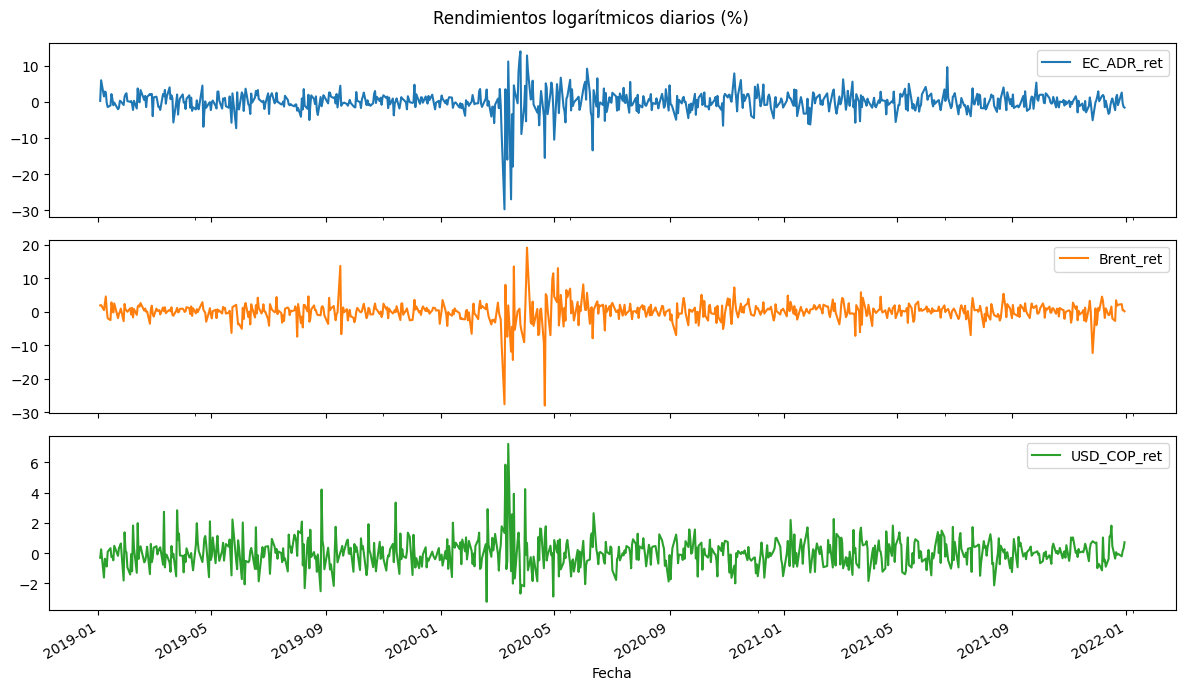


--- MATRIZ DE CORRELACIONES ---
             EC_ADR_ret  Brent_ret  USD_COP_ret
EC_ADR_ret       1.0000     0.6248       0.0299
Brent_ret        0.6248     1.0000       0.0497
USD_COP_ret      0.0299     0.0497       1.0000

--- PRUEBAS ADF ---

Variable: EC_ADR_ret
Estadístico ADF: -7.7751 | Valor p: 0.000000
Conclusión: Serie Estacionaria (Rechaza H0 al 5%)

Variable: Brent_ret
Estadístico ADF: -5.5067 | Valor p: 0.000002
Conclusión: Serie Estacionaria (Rechaza H0 al 5%)

Variable: USD_COP_ret
Estadístico ADF: -18.6219 | Valor p: 0.000000
Conclusión: Serie Estacionaria (Rechaza H0 al 5%)


/tmp/ipykernel_6879/2901053573.py:59: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(rendimientos[col])
/tmp/ipykernel_6879/2901053573.py:59: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(rendimientos[col])
/tmp/ipykernel_6879/2901053573.py:59: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autola


--- SELECCIÓN DE REZAGOS ---
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        4.002       4.020       54.68       4.009
1        3.767      3.841*       43.24       3.795
2        3.717       3.847       41.12       3.767
3        3.692       3.878       40.12      3.764*
4        3.680       3.922       39.65       3.773
5        3.685       3.982       39.84       3.799
6       3.659*       4.013      38.83*       3.795
7        3.661       4.070       38.91       3.819
8        3.667       4.132       39.15       3.847
9        3.670       4.191       39.27       3.871
10       3.683       4.259       39.75       3.905
--------------------------------------------------

Rezago seleccionado por AIC: 6

--- RESULTADOS DEL MODELO VAR ---
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 10, Nov, 202

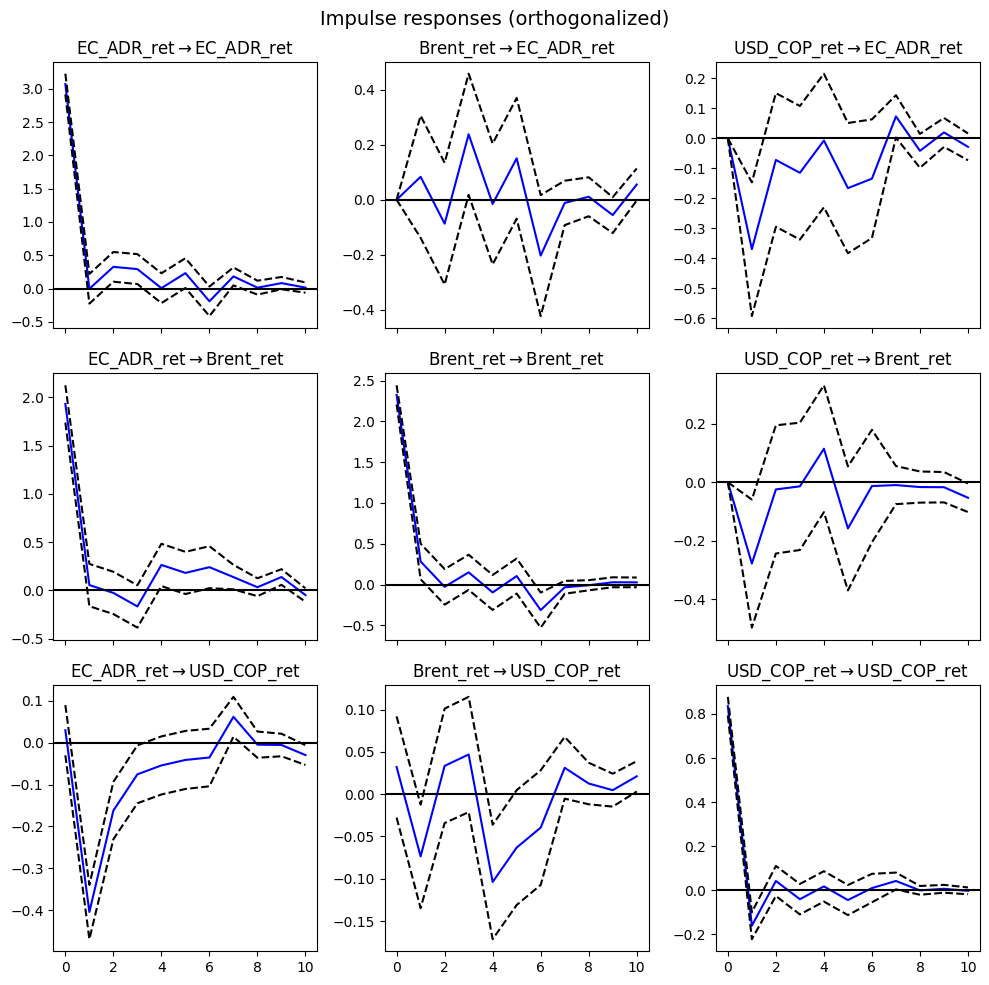


--- PRUEBAS DE CAUSALIDAD DE GRANGER ---

¿EC_ADR_ret ayuda a predecir Brent_ret? -> Valor p: 0.0008 (Significativo)

¿EC_ADR_ret ayuda a predecir USD_COP_ret? -> Valor p: 0.0000 (Significativo)

¿Brent_ret ayuda a predecir EC_ADR_ret? -> Valor p: 0.0311 (Significativo)

¿Brent_ret ayuda a predecir USD_COP_ret? -> Valor p: 0.0037 (Significativo)

¿USD_COP_ret ayuda a predecir EC_ADR_ret? -> Valor p: 0.0169 (Significativo)

¿USD_COP_ret ayuda a predecir Brent_ret? -> Valor p: 0.1880 (No significativo)

Proceso terminado con éxito. Archivo 'resumen_modelo_VAR.txt' guardado.


In [ ]:
# ==========================================
# 1. IMPORTAR LIBRERÍAS
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller

# ==========================================
# 2. CARGAR Y ORGANIZAR BASE DE DATOS
# ==========================================
ruta = "base_precios_depurada_2019_2021_LosEndeudados_v2.csv"
df = pd.read_csv(ruta, sep=",")
df["Fecha"] = pd.to_datetime(df["Fecha"])
df = df.sort_values("Fecha").set_index("Fecha")

variables = ["EC_ADR_USD_Cierre", "Brent_USD_Cierre", "USD_COP_Cierre"]
precios = df[variables].copy()

# ==========================================
# 3. VALIDACIÓN DE PRECIOS
# ==========================================
print("\n--- VALIDACIÓN DE PRECIOS ---")
print("Dimensiones:", precios.shape)
print("\nDatos faltantes:\n", precios.isna().sum())
print("\nFechas duplicadas:", precios.index.duplicated().sum())

if (precios <= 0).any().any():
    raise ValueError("Hay precios iguales o inferiores a cero.")

# ==========================================
# 4. CALCULAR RENDIMIENTOS LOGARÍTMICOS (%)
# ==========================================
rendimientos = 100 * np.log(precios / precios.shift(1)).dropna()
rendimientos.columns = ["EC_ADR_ret", "Brent_ret", "USD_COP_ret"]

print("\n--- RENDIMIENTOS ---")
print(f"Observaciones: {len(rendimientos)}")
print(f"Periodo: {rendimientos.index.min().date()} a {rendimientos.index.max().date()}")
print("\nEstadísticas descriptivas:\n", rendimientos.describe().round(4))
rendimientos.to_csv("rendimientos_2019_2021.csv")

# ==========================================
# 5. ANÁLISIS EXPLORATORIO Y CORRELACIONES
# ==========================================
rendimientos.plot(subplots=True, figsize=(12, 7), title="Rendimientos logarítmicos diarios (%)")
plt.tight_layout()
plt.show()

print("\n--- MATRIZ DE CORRELACIONES ---")
print(rendimientos.corr().round(4))

# ==========================================
# 6. PRUEBAS DE ESTACIONARIEDAD (ADF)
# ==========================================
print("\n--- PRUEBAS ADF ---")
for col in rendimientos.columns:
    res = adfuller(rendimientos[col])
    print(f"\nVariable: {col}")
    print(f"Estadístico ADF: {res[0]:.4f} | Valor p: {res[1]:.6f}")
    if res[1] < 0.05:
        print("Conclusión: Serie Estacionaria (Rechaza H0 al 5%)")
    else:
        print("Conclusión: Serie No Estacionaria (No rechaza H0)")

# ==========================================
# 7. SELECCIÓN DE REZAGOS
# ==========================================
modelo_var = VAR(rendimientos)
seleccion = modelo_var.select_order(maxlags=10)
print("\n--- SELECCIÓN DE REZAGOS ---")
print(seleccion.summary())

rezago = seleccion.selected_orders["aic"]
print(f"\nRezago seleccionado por AIC: {rezago}")

# ==========================================
# 8. ESTIMAR MODELO VAR
# ==========================================
resultado_var = modelo_var.fit(rezago, trend="c")
print("\n--- RESULTADOS DEL MODELO VAR ---")
print(resultado_var.summary())

# ==========================================
# 9. VERIFICAR ESTABILIDAD
# ==========================================
print("\n--- ESTABILIDAD DEL SISTEMA ---")
if resultado_var.is_stable():
    print("El modelo cumple la condición de estabilidad (raíces dentro del círculo unitario).")
else:
    print("ADVERTENCIA: El modelo no cumple la condición de estabilidad.")

# ==========================================
# 10. DIAGNÓSTICO DE RESIDUOS (AUTOCORRELACIÓN Y NORMALIDAD)
# ==========================================
print("\n--- DIAGNÓSTICO DE RESIDUOS ---")
nlags_diag = max(10, resultado_var.k_ar + 1)
prueba_residuos = resultado_var.test_whiteness(nlags=nlags_diag, adjusted=True)
print(prueba_residuos.summary())

prueba_normalidad = resultado_var.test_normality()
print(prueba_normalidad.summary())

# ==========================================
# 11. FUNCIONES DE IMPULSO-RESPUESTA (IRF)
# ==========================================
print("\n--- GENERANDO RESPUESTAS AL IMPULSO ---")
impulso = resultado_var.irf(10)
impulso.plot(orth=True)
plt.tight_layout()
plt.show()

# ==========================================
# 12. CAUSALIDAD DE GRANGER
# ==========================================
print("\n--- PRUEBAS DE CAUSALIDAD DE GRANGER ---")
for causa in rendimientos.columns:
    for efecto in rendimientos.columns:
        if causa != efecto:
            prueba = resultado_var.test_causality(caused=efecto, causing=[causa], kind="f")
            p_val = prueba.pvalue
            print(f"\n¿{causa} ayuda a predecir {efecto}? -> Valor p: {p_val:.4f} ({'Significativo' if p_val < 0.05 else 'No significativo'})")

# ==========================================
# 13. GUARDAR RESULTADOS EN ARCHIVO DE TEXTO
# ==========================================
with open("resumen_modelo_VAR.txt", "w", encoding="utf-8") as f:
    f.write(str(resultado_var.summary()) + "\n\n")
    f.write(str(prueba_residuos.summary()) + "\n\n")
    f.write(str(prueba_normalidad.summary()) + "\n")

print("\nProceso terminado con éxito. Archivo 'resumen_modelo_VAR.txt' guardado.")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller

# 1. Cargar y organizar datos
ruta = "base_precios_depurada_2019_2021_LosEndeudados_v2.csv"
df = pd.read_csv(ruta, sep=",")
df["Fecha"] = pd.to_datetime(df["Fecha"])
df = df.sort_values("Fecha").set_index("Fecha")

variables = ["EC_ADR_USD_Cierre", "Brent_USD_Cierre", "USD_COP_Cierre"]
precios = df[variables].copy()

# 2. Rendimientos logarítmicos continuos (%)
rendimientos = 100 * np.log(precios / precios.shift(1)).dropna()
rendimientos.columns = ["EC_ADR_ret", "Brent_ret", "USD_COP_ret"]

print("--- RENDIMIENTOS CALCULADOS ---")
print(f"Observaciones: {len(rendimientos)}")
print(rendimientos.describe().round(4))

# 3. Matriz de correlaciones
print("\n--- MATRIZ DE CORRELACIONES ---")
print(rendimientos.corr().round(4))

# 4. Pruebas ADF de raíz unitaria
print("\n--- PRUEBAS ADF ---")
for col in rendimientos.columns:
    res = adfuller(rendimientos[col])
    print(f"{col}: Estadístico = {res[0]:.4f}, Valor p = {res[1]:.6f}")

# 5. Selección de rezagos
modelo_var = VAR(rendimientos)
seleccion = modelo_var.select_order(maxlags=10)
print("\n--- CRITERIOS DE INFORMACIÓN ---")
print(seleccion.summary())

rezago = seleccion.selected_orders["aic"]
print(f"\nRezago óptimo según AIC: {rezago}")

# 6. Estimación del VAR
resultado_var = modelo_var.fit(rezago, trend="c")
print("\n--- RESUMEN DEL MODELO VAR ---")
print(resultado_var.summary())

# 7. Diagnósticos: Estabilidad, Autocorrelación y Normalidad
print("\n--- DIAGNÓSTICOS DEL MODELO ---")
print(f"¿Es estable el VAR?: {resultado_var.is_stable()}")

nlags_diag = max(10, resultado_var.k_ar + 1)
prueba_residuos = resultado_var.test_whiteness(nlags=nlags_diag, adjusted=True)
print("\nPrueba de Autocorrelación (Portmanteau):")
print(prueba_residuos.summary())

prueba_normalidad = resultado_var.test_normality()
print("\nPrueba de Normalidad de Residuos:")
print(prueba_normalidad.summary())

# 8. Causalidad de Granger
print("\n--- CAUSALIDAD DE GRANGER ---")
for causa in rendimientos.columns:
    for efecto in rendimientos.columns:
        if causa != efecto:
            prueba = resultado_var.test_causality(caused=efecto, causing=[causa], kind="f")
            print(f"¿{causa} predice a {efecto}?: Valor p = {prueba.pvalue:.4f}")

# 9. Guardar archivo de resultados
with open("resumen_modelo_VAR.txt", "w", encoding="utf-8") as f:
    f.write(str(resultado_var.summary()) + "\n\n")
    f.write(str(prueba_residuos.summary()) + "\n\n")
    f.write(str(prueba_normalidad.summary()) + "\n")

print("\n¡Ejecución completada con éxito!")

--- RENDIMIENTOS CALCULADOS ---
Observaciones: 754
       EC_ADR_ret  Brent_ret  USD_COP_ret
count    754.0000   754.0000     754.0000
mean      -0.0311     0.0488       0.0289
std        3.1398     3.0751       0.9704
min      -29.7275   -27.9761      -3.2214
25%       -1.2394    -0.9524      -0.5024
50%       -0.0521     0.2919       0.0045
75%        1.4338     1.2683       0.5155
max       13.9216    19.0774       7.2109

--- MATRIZ DE CORRELACIONES ---
             EC_ADR_ret  Brent_ret  USD_COP_ret
EC_ADR_ret       1.0000     0.6248       0.0299
Brent_ret        0.6248     1.0000       0.0497
USD_COP_ret      0.0299     0.0497       1.0000

--- PRUEBAS ADF ---
EC_ADR_ret: Estadístico = -7.7751, Valor p = 0.000000
Brent_ret: Estadístico = -5.5067, Valor p = 0.000002
USD_COP_ret: Estadístico = -18.6219, Valor p = 0.000000

--- CRITERIOS DE INFORMACIÓN ---
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------

/tmp/ipykernel_6879/4207242150.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(rendimientos[col])
/tmp/ipykernel_6879/4207242150.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(rendimientos[col])
/tmp/ipykernel_6879/4207242150.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autola

¿USD_COP_ret predice a EC_ADR_ret?: Valor p = 0.0169
¿USD_COP_ret predice a Brent_ret?: Valor p = 0.1880

¡Ejecución completada con éxito!


In [ ]:
from statsmodels.tsa.api import VAR

modelo = VAR(rendimientos)

for p in [1, 3, 6]:
    resultado = modelo.fit(p, trend="c")

    print("\n" + "=" * 45)
    print(f"RESULTADOS VAR({p})")
    print("=" * 45)

    print("Observaciones:", resultado.nobs)
    print("Estabilidad:", resultado.is_stable())

    prueba_auto = resultado.test_whiteness(nlags=10, adjusted=True)
    prueba_normal = resultado.test_normality()

    print(f"Autocorrelación (Portmanteau) - valor p: {prueba_auto.pvalue:.5f}")
    print(f"Normalidad (Jarque-Bera) - valor p:      {prueba_normal.pvalue:.5f}")

    print(f"AIC:  {resultado.aic:.4f}")
    print(f"BIC:  {resultado.bic:.4f}")
    print(f"HQIC: {resultado.hqic:.4f}")


RESULTADOS VAR(1)
Observaciones: 753
Estabilidad: True
Autocorrelación (Portmanteau) - valor p: 0.00000
Normalidad (Jarque-Bera) - valor p:      0.00000
AIC:  3.7456
BIC:  3.8193
HQIC: 3.7739

RESULTADOS VAR(3)
Observaciones: 751
Estabilidad: True
Autocorrelación (Portmanteau) - valor p: 0.00000
Normalidad (Jarque-Bera) - valor p:      0.00000
AIC:  3.6714
BIC:  3.8560
HQIC: 3.7425

RESULTADOS VAR(6)
Observaciones: 748
Estabilidad: True
Autocorrelación (Portmanteau) - valor p: 0.02552
Normalidad (Jarque-Bera) - valor p:      0.00000
AIC:  3.6469
BIC:  3.9988
HQIC: 3.7825


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [ ]:
# 1. IMPORTAR LIBRERÍAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR

# 2. CARGAR BASE DE PRECIOS DIRECTAMENTE
ruta = "base_precios_depurada_2019_2021_LosEndeudados_v2.csv"
df = pd.read_csv(ruta)

# Convertir fecha y ordenar
df["Fecha"] = pd.to_datetime(df["Fecha"])
df = df.sort_values("Fecha").set_index("Fecha")

print("Dimensiones:", df.shape)
print("\nPrimeras filas:")
display(df.head())

# 3. CALCULAR RENDIMIENTOS LOGARÍTMICOS (%)
variables = ["EC_ADR_USD_Cierre", "Brent_USD_Cierre", "USD_COP_Cierre"]
precios = df[variables]

rendimientos = 100 * np.log(precios / precios.shift(1)).dropna()
rendimientos.columns = ["EC_ADR_ret", "Brent_ret", "USD_COP_ret"]

print("\nObservaciones de rendimientos:", len(rendimientos))
display(rendimientos.head())

# 4. COMPARACIÓN DE MODELOS VAR(1), VAR(3) Y VAR(6)
modelo = VAR(rendimientos)

for p in [1, 3, 6]:
    resultado = modelo.fit(p, trend="c")

    print("\n" + "=" * 45)
    print(f"RESULTADOS VAR({p})")
    print("=" * 45)

    print("Observaciones:", resultado.nobs)
    print("Estabilidad:", resultado.is_stable())

    # Diagnóstico de residuos
    prueba_auto = resultado.test_whiteness(nlags=10, adjusted=True)
    prueba_normal = resultado.test_normality()

    print(f"Autocorrelación (Portmanteau) - valor p: {prueba_auto.pvalue:.5f}")
    print(f"Normalidad (Jarque-Bera) - valor p:      {prueba_normal.pvalue:.5f}")

    # Criterios de información
    print(f"AIC:  {resultado.aic:.4f}")
    print(f"BIC:  {resultado.bic:.4f}")
    print(f"HQIC: {resultado.hqic:.4f}")

Dimensiones: (755, 3)

Primeras filas:


,EC_ADR_USD_Cierre,Brent_USD_Cierre,USD_COP_Cierre
Fecha,,,
2019-01-02,16.46,54.91,3245.0
2019-01-03,16.50,55.95,3235.0
2019-01-04,17.51,57.06,3243.0
2019-01-07,17.77,57.33,3191.0
2019-01-08,18.28,58.72,3179.0



Observaciones de rendimientos: 754


,EC_ADR_ret,Brent_ret,USD_COP_ret
Fecha,,,
2019-01-03,0.242719,1.876295,-0.308642
2019-01-04,5.941177,1.964491,0.246990
2019-01-07,1.473950,0.472070,-1.616448
2019-01-08,2.829592,2.395634,-0.376767
2019-01-09,2.591938,4.528070,-0.589972



RESULTADOS VAR(1)
Observaciones: 753
Estabilidad: True
Autocorrelación (Portmanteau) - valor p: 0.00000
Normalidad (Jarque-Bera) - valor p:      0.00000
AIC:  3.7456
BIC:  3.8193
HQIC: 3.7739

RESULTADOS VAR(3)
Observaciones: 751
Estabilidad: True
Autocorrelación (Portmanteau) - valor p: 0.00000
Normalidad (Jarque-Bera) - valor p:      0.00000
AIC:  3.6714
BIC:  3.8560
HQIC: 3.7425

RESULTADOS VAR(6)
Observaciones: 748
Estabilidad: True
Autocorrelación (Portmanteau) - valor p: 0.02552
Normalidad (Jarque-Bera) - valor p:      0.00000
AIC:  3.6469
BIC:  3.9988
HQIC: 3.7825


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [ ]:
# ==========================================
# 4. ESTIMAR VAR(6)
# ==========================================
modelo = VAR(rendimientos)
resultado = modelo.fit(6, trend="c")
print(resultado.summary())

# ==========================================
# 5. DIAGNÓSTICOS DEL MODELO VAR(6)
# ==========================================
print("\n¿VAR ESTABLE?:", resultado.is_stable())

# Prueba de autocorrelación (Portmanteau / Whiteness)
prueba_auto = resultado.test_whiteness(nlags=10, adjusted=True)
print("\nAutocorrelación residual:")
print(prueba_auto.summary())

# Prueba de normalidad de residuos (Jarque-Bera)
prueba_normal = resultado.test_normality()
print("\nNormalidad residual:")
print(prueba_normal.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 10, Nov, 2026
Time:                     02:18:32
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                    3.99879
Nobs:                     748.000    HQIC:                   3.78253
Log likelihood:          -4491.05    FPE:                    38.3579
AIC:                      3.64693    Det(Omega_mle):         35.5774
--------------------------------------------------------------------
Results for equation EC_ADR_ret
                    coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------------
const                 -0.013707         0.112907           -0.121           0.903
L1.EC_ADR_ret         -0.023080         0.047578           -0.485           0.628
L1.Brent_ret           0.041933         0.048364   

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


2. markov

Límite inferior (Adverso <= -0.8489%): -0.8489%
Límite superior (Favorable > 0.9553%): 0.9553%

Frecuencia de estados observados:
Estado
Adverso      251
Neutral      251
Favorable    252
Name: count, dtype: int64


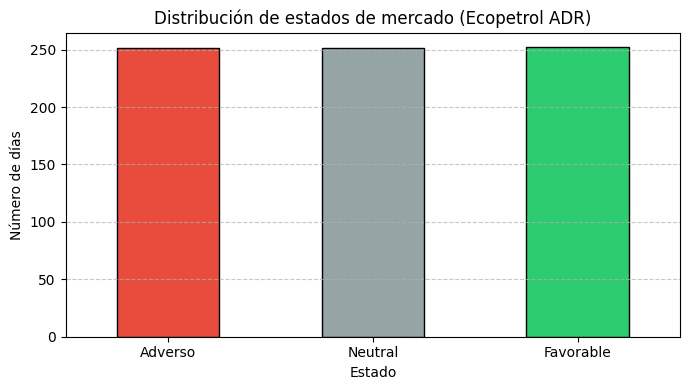

In [ ]:
# ==========================================
# 6. DEFINIR ESTADOS DE MERCADO
# ==========================================
serie = rendimientos["EC_ADR_ret"]

# Calcular puntos de corte por terciles empíricos (33.3% y 66.7%)
limite_inferior = float(serie.quantile(1/3))
limite_superior = float(serie.quantile(2/3))

# Clasificar observaciones en los 3 estados
condiciones = [
    serie <= limite_inferior,
    (serie > limite_inferior) & (serie <= limite_superior),
    serie > limite_superior
]

estados = ["Adverso", "Neutral", "Favorable"]

# default="Desconocido" evita el conflicto de tipos en NumPy reciente
rendimientos["Estado"] = np.select(condiciones, estados, default="Desconocido")

print(f"Límite inferior (Adverso <= {limite_inferior:.4f}%): {limite_inferior:.4f}%")
print(f"Límite superior (Favorable > {limite_superior:.4f}%): {limite_superior:.4f}%")
print("\nFrecuencia de estados observados:")
print(rendimientos["Estado"].value_counts().reindex(estados))

# Visualizar distribución
plt.figure(figsize=(7, 4))
rendimientos["Estado"].value_counts().reindex(estados).plot(
    kind="bar",
    color=["#e74c3c", "#95a5a6", "#2ecc71"],
    edgecolor="black"
)
plt.title("Distribución de estados de mercado (Ecopetrol ADR)")
plt.xlabel("Estado")
plt.ylabel("Número de días")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 7. MATRIZ DE TRANSICIÓN DE MARKOV
# ==========================================
orden = ["Adverso", "Neutral", "Favorable"]

# Estado actual (t) y estado siguiente (t+1)
estado_actual = rendimientos["Estado"].iloc[:-1].values
estado_siguiente = rendimientos["Estado"].iloc[1:].values

# Matriz de frecuencias observadas
transiciones = pd.crosstab(
    estado_actual,
    estado_siguiente,
    rownames=["Estado_t"],
    colnames=["Estado_t+1"]
)

# Garantizar orden de filas y columnas
transiciones = transiciones.reindex(
    index=orden,
    columns=orden,
    fill_value=0
)

print("--- MATRIZ DE FRECUENCIAS (CONTEO DE DÍAS) ---")
display(transiciones)

# Convertir frecuencias en probabilidades de transición condicionadas por fila
matriz_markov = transiciones.div(transiciones.sum(axis=1), axis=0)

print("\n--- MATRIZ DE PROBABILIDADES DE TRANSICIÓN (P) ---")
display(matriz_markov.round(4))

# Verificación de propiedad estocástica: cada fila debe sumar exactamente 1
print("\nSuma de probabilidades por fila (debe ser 1.0):")
print(matriz_markov.sum(axis=1).round(4))

--- MATRIZ DE FRECUENCIAS (CONTEO DE DÍAS) ---


Estado_t+1,Adverso,Neutral,Favorable
Estado_t,,,
Adverso,83,82,85
Neutral,85,90,76
Favorable,83,78,91



--- MATRIZ DE PROBABILIDADES DE TRANSICIÓN (P) ---


Estado_t+1,Adverso,Neutral,Favorable
Estado_t,,,
Adverso,0.3320,0.3280,0.3400
Neutral,0.3386,0.3586,0.3028
Favorable,0.3294,0.3095,0.3611



Suma de probabilidades por fila (debe ser 1.0):
Estado_t
Adverso      1.0
Neutral      1.0
Favorable    1.0
dtype: float64


In [ ]:
# ==========================================
# 8. DURACIÓN ESPERADA DE LOS ESTADOS
# ==========================================
duracion = {}

for estado in orden:
    prob_permanecer = matriz_markov.loc[estado, estado]
    if prob_permanecer == 1:
        duracion[estado] = np.inf
    else:
        duracion[estado] = 1 / (1 - prob_permanecer)

duracion_df = pd.DataFrame.from_dict(
    duracion,
    orient="index",
    columns=["Duracion esperada (dias de observacion)"]
)

print("--- DURACIÓN ESPERADA DE CADA ESTADO ---")
display(duracion_df.round(2))

--- DURACIÓN ESPERADA DE CADA ESTADO ---


,Duracion esperada (dias de observacion)
Adverso,1.50
Neutral,1.56
Favorable,1.57


In [ ]:
# ==========================================
# 9. DISTRIBUCIÓN ESTACIONARIA
# ==========================================
P = matriz_markov.values

# Cálculo de valores y vectores propios de la matriz transpuesta P^T
valores, vectores = np.linalg.eig(P.T)

# Identificar el vector propio asociado al valor propio lambda = 1
indice = np.argmin(np.abs(valores - 1.0))
vector = np.real(vectores[:, indice])

# Normalizar el vector para que las probabilidades sumen 1
distribucion = vector / vector.sum()

distribucion_estacionaria = pd.Series(
    distribucion,
    index=orden,
    name="Probabilidad estacionaria"
)

print("--- DISTRIBUCIÓN ESTACIONARIA DE LARGO PLAZO (\u03c0) ---")
display(distribucion_estacionaria.round(4))

# Verificación matemática: \pi * P \approx \pi
pi = distribucion_estacionaria.values
verificacion = np.allclose(pi @ P, pi)
print(f"\n¿Cumple la condición estacionaria \u03c0 * P = \u03c0?: {verificacion}")

--- DISTRIBUCIÓN ESTACIONARIA DE LARGO PLAZO (π) ---


,Probabilidad estacionaria
Adverso,0.3333
Neutral,0.3320
Favorable,0.3347



¿Cumple la condición estacionaria π * P = π?: True


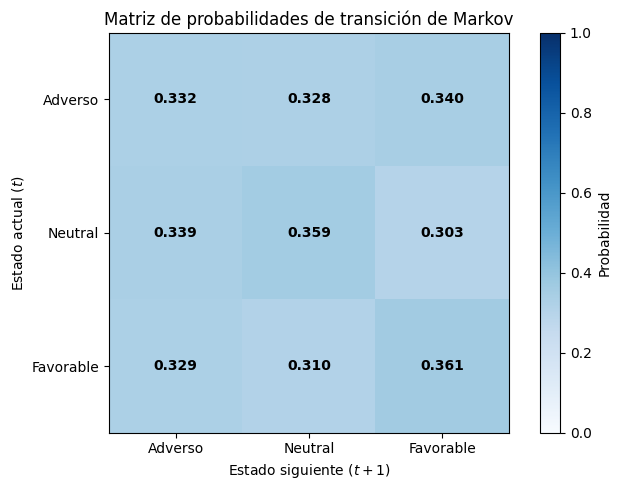

In [ ]:
# ==========================================
# 10. VISUALIZACIÓN DE LA MATRIZ DE MARKOV
# ==========================================
plt.figure(figsize=(7, 5))
plt.imshow(
    matriz_markov.values,
    cmap="Blues",
    vmin=0,
    vmax=1
)
plt.colorbar(label="Probabilidad")
plt.xticks(range(3), orden)
plt.yticks(range(3), orden)
plt.xlabel("Estado siguiente ($t+1$)")
plt.ylabel("Estado actual ($t$)")
plt.title("Matriz de probabilidades de transición de Markov")

# Anotación numérica en cada celda
for i in range(3):
    for j in range(3):
        valor = matriz_markov.iloc[i, j]
        # Cambia el color del texto si la celda es muy oscura para facilitar lectura
        color_texto = "white" if valor > 0.5 else "black"
        plt.text(
            j, i,
            f"{valor:.3f}",
            ha="center",
            va="center",
            color=color_texto,
            fontweight="bold"
        )

plt.tight_layout()
plt.show()

3. MONTECARLO

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Parámetros de simulación
CAPITAL_INICIAL = 10_000_000
HORIZONTE = 21
N_SIMULACIONES = 10_000
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

# Cargar CSV
nombre_defecto = "base_precios_depurada_2019_2021_LosEndeudados_v2.csv"
if os.path.exists(nombre_defecto):
    nombre_archivo = nombre_defecto
    print(f"Cargando archivo existente en Colab: {nombre_archivo}")
else:
    uploaded = files.upload()
    nombre_archivo = next(iter(uploaded))

# Detectar si el archivo usa separador ',' o ';'
with open(nombre_archivo, 'r') as f:
    primera_linea = f.readline()
    separador = ';' if ';' in primera_linea else ','

df = pd.read_csv(nombre_archivo, sep=separador)

# Asegurar formato de Fecha
df["Fecha"] = pd.to_datetime(df["Fecha"], format="mixed", dayfirst=True)
df = df.sort_values("Fecha").set_index("Fecha")

cols_precios = ["EC_ADR_USD_Cierre", "Brent_USD_Cierre", "USD_COP_Cierre"]

# Limpieza robusta de números
for c in cols_precios:
    if c in df.columns:
        if df[c].dtype == "object":
            # Si tiene múltiples puntos (ej: 32.450.000) los eliminamos
            df[c] = df[c].astype(str).str.replace(".", "", regex=False)
            # Si usa coma como decimal, la reemplazamos por punto
            df[c] = df[c].str.replace(",", ".", regex=False)
        df[c] = pd.to_numeric(df[c], errors="coerce")

precios = df[cols_precios].copy()

if precios.isna().any().any() or (precios <= 0).any().any():
    # Mostrar dónde están los fallos si los hay para diagnóstico
    print("Valores nulos por columna:\n", precios.isna().sum())
    print("Valores <= 0 por columna:\n", (precios <= 0).sum())
    raise ValueError("Hay precios faltantes o no positivos después de la depuración.")

# Rendimientos logarítmicos porcentuales
rendimientos = 100 * np.log(precios / precios.shift(1))
rendimientos = rendimientos.dropna()
rendimientos.columns = [
    "EC_ADR_ret",
    "Brent_ret",
    "USD_COP_ret"
]

print("Observaciones disponibles:", len(rendimientos))
display(rendimientos.head())


Cargando archivo existente en Colab: base_precios_depurada_2019_2021_LosEndeudados_v2.csv
Observaciones disponibles: 754


,EC_ADR_ret,Brent_ret,USD_COP_ret
Fecha,,,
2019-01-03,0.242719,1.876295,-0.308642
2019-01-04,5.941177,1.964491,0.246990
2019-01-07,1.473950,0.472070,-1.616448
2019-01-08,2.829592,2.395634,-0.376767
2019-01-09,2.591938,4.528070,-0.589972


In [5]:
# ============================================================
# DEFINICIÓN DE ESTADOS
# ============================================================
serie_ec = rendimientos["EC_ADR_ret"]

limite_inferior = float(serie_ec.quantile(1/3))
limite_superior = float(serie_ec.quantile(2/3))

orden_estados = [
    "Adverso",
    "Neutral",
    "Favorable"
]

condiciones = [
    serie_ec <= limite_inferior,
    (serie_ec > limite_inferior) & (serie_ec <= limite_superior),
    serie_ec > limite_superior
]

# default="Neutral" previene el TypeError en versiones recientes de NumPy
rendimientos["Estado"] = np.select(
    condiciones,
    orden_estados,
    default="Neutral"
)

print("Límite adverso:", round(limite_inferior, 4), "%")
print("Límite favorable:", round(limite_superior, 4), "%")
print("\nDistribución de estados:")
print(rendimientos["Estado"].value_counts().reindex(orden_estados))

Límite adverso: -0.8489 %
Límite favorable: 0.9553 %

Distribución de estados:
Estado
Adverso      251
Neutral      251
Favorable    252
Name: count, dtype: int64


In [7]:
# ============================================================
# MATRIZ DE TRANSICIÓN DE MARKOV
# ============================================================
# Se usa .to_numpy() para evitar que Pandas cruce el índice de fechas (t vs t+1)
transiciones = pd.crosstab(
    rendimientos["Estado"].iloc[:-1].to_numpy(),
    rendimientos["Estado"].iloc[1:].to_numpy(),
    rownames=["Estado actual (t)"],
    colnames=["Estado siguiente (t+1)"]
)

transiciones = transiciones.reindex(
    index=orden_estados,
    columns=orden_estados,
    fill_value=0
)

matriz_markov = transiciones.div(
    transiciones.sum(axis=1),
    axis=0
)

P = matriz_markov.to_numpy()

print("MATRIZ DE TRANSICIÓN:")
display(matriz_markov.round(4))

print("\nSuma de filas:")
print(P.sum(axis=1))

if not np.allclose(P.sum(axis=1), 1):
    raise ValueError("La matriz de transición no suma 1 por fila.")

MATRIZ DE TRANSICIÓN:


Estado siguiente (t+1),Adverso,Neutral,Favorable
Estado actual (t),,,
Adverso,0.3320,0.3280,0.3400
Neutral,0.3386,0.3586,0.3028
Favorable,0.3294,0.3095,0.3611



Suma de filas:
[1. 1. 1.]


In [8]:
# ============================================================
# REMUESTREO HISTÓRICO CONDICIONADO POR ESTADO
# ============================================================
columnas_retornos = [
    "EC_ADR_ret",
    "Brent_ret",
    "USD_COP_ret"
]

grupos_historicos = {}

for estado in orden_estados:
    grupo = rendimientos.loc[
        rendimientos["Estado"] == estado,
        columnas_retornos
    ].to_numpy()

    if len(grupo) == 0:
        raise ValueError(f"No hay observaciones para {estado}")

    grupos_historicos[estado] = grupo
    print(f"{estado} - observaciones históricas: {len(grupo)}")

# Estado inicial: último estado observado
estado_inicial = rendimientos["Estado"].iloc[-1]
print("\nÚltimo estado observado:", estado_inicial)

Adverso - observaciones históricas: 251
Neutral - observaciones históricas: 251
Favorable - observaciones históricas: 252

Último estado observado: Adverso


In [9]:
# ============================================================
# SIMULACIÓN MONTE CARLO
# ============================================================
resultados = []

# Índice numérico del estado inicial
estado_actual_inicial = orden_estados.index(estado_inicial)

for simulacion in range(N_SIMULACIONES):
    estado_actual = estado_actual_inicial
    suma_ec = 0.0
    suma_brent = 0.0
    suma_usd_cop = 0.0
    suma_portafolio = 0.0

    for dia in range(HORIZONTE):
        # 1. Simular el siguiente estado
        estado_siguiente = rng.choice(
            len(orden_estados),
            p=P[estado_actual]
        )
        nombre_estado = orden_estados[estado_siguiente]

        # 2. Extraer vector conjunto del estado simulado
        grupo = grupos_historicos[nombre_estado]
        indice = rng.integers(0, len(grupo))
        retorno_ec, retorno_brent, retorno_cambio = grupo[indice]

        # 3. Acumular rendimientos logarítmicos
        suma_ec += retorno_ec
        suma_brent += retorno_brent
        suma_usd_cop += retorno_cambio

        # Rendimiento de inversión en COP
        retorno_cop = retorno_ec + retorno_cambio
        suma_portafolio += retorno_cop

        # Actualizar estado
        estado_actual = estado_siguiente

    # 4. Calcular valor final de la inversión (fuera del bucle diario)
    valor_final = CAPITAL_INICIAL * np.exp(
        suma_portafolio / 100
    )
    perdida = CAPITAL_INICIAL - valor_final

    resultados.append({
        "Simulacion": simulacion + 1,
        "Retorno_EC_pct": suma_ec,
        "Retorno_Brent_pct": suma_brent,
        "Retorno_USD_COP_pct": suma_usd_cop,
        "Retorno_Portafolio_COP_pct": suma_portafolio,
        "Valor_Final_COP": valor_final,
        "Perdida_COP": perdida
    })

resultados_mc = pd.DataFrame(resultados)
print("Simulaciones realizadas:", len(resultados_mc))
display(resultados_mc.head())

Simulaciones realizadas: 10000


,Simulacion,Retorno_EC_pct,Retorno_Brent_pct,Retorno_USD_COP_pct,Retorno_Portafolio_COP_pct,Valor_Final_COP,Perdida_COP
0,1,35.598242,21.577626,7.838631,43.436873,1.543988e+07,-5.439881e+06
1,2,-4.160283,-6.451013,1.302828,-2.857455,9.718298e+06,2.817015e+05
2,3,-1.207068,8.015096,0.739530,-0.467539,9.953355e+06,4.664475e+04
3,4,-10.965848,-11.489391,8.437215,-2.528633,9.750307e+06,2.496931e+05
4,5,-6.138003,-5.298060,0.145641,-5.992362,9.418365e+06,5.816353e+05


In [10]:
# ============================================================
# MEDIDAS DE RIESGO
# ============================================================
perdidas = resultados_mc["Perdida_COP"]

def calcular_riesgo(perdidas, confianza):
    var = perdidas.quantile(confianza)
    # Promedio de pérdidas en la cola más adversa
    es = perdidas[perdidas >= var].mean()
    return var, es

var_95, es_95 = calcular_riesgo(perdidas, 0.95)
var_99, es_99 = calcular_riesgo(perdidas, 0.99)

tabla_riesgo = pd.DataFrame({
    "Indicador": [
        "VaR 95%",
        "Expected Shortfall 95%",
        "VaR 99%",
        "Expected Shortfall 99%"
    ],
    "Valor_COP": [
        var_95,
        es_95,
        var_99,
        es_99
    ]
})

print("RESULTADOS DE RIESGO:")
display(tabla_riesgo.style.format({
    "Valor_COP": "${:,.0f}"
}))

# Reserva propuesta: Expected Shortfall al 99%
reserva_recomendada = max(0, es_99)
print(
    "\nRESERVA DE RIESGO PROPUESTA (ES 99%):",
    f"${reserva_recomendada:,.0f} COP"
)

RESULTADOS DE RIESGO:


,Indicador,Valor_COP
0,VaR 95%,"$2,353,846"
1,Expected Shortfall 95%,"$3,036,978"
2,VaR 99%,"$3,499,062"
3,Expected Shortfall 99%,"$4,018,274"



RESERVA DE RIESGO PROPUESTA (ES 99%): $4,018,274 COP


In [11]:
# ============================================================
# RESUMEN DE RESULTADOS
# ============================================================
resumen = pd.DataFrame({
    "Indicador": [
        "Capital inicial",
        "Valor final promedio",
        "Valor final mínimo",
        "Valor final máximo",
        "Pérdida promedio",
        "Mediana de pérdidas",
        "Probabilidad de pérdida (%)"
    ],
    "Valor_COP": [
        CAPITAL_INICIAL,
        resultados_mc["Valor_Final_COP"].mean(),
        resultados_mc["Valor_Final_COP"].min(),
        resultados_mc["Valor_Final_COP"].max(),
        perdidas.mean(),
        perdidas.median(),
        (perdidas > 0).mean() * 100
    ]
})

display(resumen.round(2))

,Indicador,Valor_COP
0,Capital inicial,10000000.00
1,Valor final promedio,10122404.41
2,Valor final mínimo,4538951.14
3,Valor final máximo,17405278.50
4,Pérdida promedio,-122404.41
5,Mediana de pérdidas,-102422.19
6,Probabilidad de pérdida (%),46.83


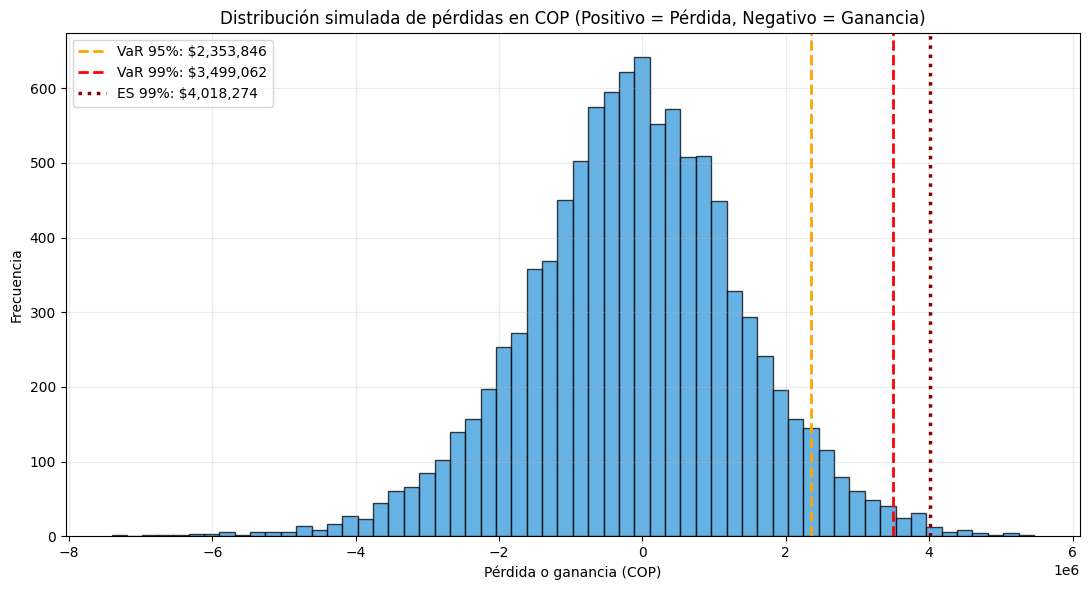

In [13]:
# ============================================================
# DISTRIBUCIÓN DE PÉRDIDAS
# ============================================================
plt.figure(figsize=(11, 6))
plt.hist(
    perdidas,
    bins=60,
    color="#3498db",
    edgecolor="black",
    alpha=0.75
)
plt.axvline(
    var_95,
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"VaR 95%: ${var_95:,.0f}"
)
plt.axvline(
    var_99,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"VaR 99%: ${var_99:,.0f}"
)
plt.axvline(
    es_99,
    color="darkred",
    linestyle=":",
    linewidth=2.5,
    label=f"ES 99%: ${es_99:,.0f}"
)
plt.title("Distribución simulada de pérdidas en COP (Positivo = Pérdida, Negativo = Ganancia)")
plt.xlabel("Pérdida o ganancia (COP)")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# EXPORTAR RESULTADOS
# ============================================================
resultados_mc.to_csv(
    "resultados_montecarlo_10000.csv",
    index=False
)

tabla_riesgo.to_csv(
    "indicadores_riesgo.csv",
    index=False
)

print("Archivos generados correctamente.")
files.download("resultados_montecarlo_10000.csv")
files.download("indicadores_riesgo.csv")

Archivos generados correctamente.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# ============================================================
# 4. CORRECCIÓN DEL FORMATO DE LA TABLA EN GOOGLE COLAB
# ============================================================
# Mostrar indicadores con formato colombiano
tabla_riesgo_final = pd.DataFrame({
    "Indicador": [
        "VaR 95%",
        "Expected Shortfall 95%",
        "VaR 99%",
        "Expected Shortfall 99%"
    ],
    "Valor_COP": [
        var_95,
        es_95,
        var_99,
        es_99
    ]
})

tabla_riesgo_final["Valor_COP"] = (
    tabla_riesgo_final["Valor_COP"]
    .round(0)
    .map(lambda x: f"${x:,.0f}".replace(",", "."))
)

display(tabla_riesgo_final)

,Indicador,Valor_COP
0,VaR 95%,$2.353.846
1,Expected Shortfall 95%,$3.036.978
2,VaR 99%,$3.499.062
3,Expected Shortfall 99%,$4.018.274


In [16]:
# Formato colombiano para la tabla de resumen
resumen_final = pd.DataFrame({
    "Indicador": [
        "Capital inicial",
        "Valor final promedio",
        "Valor final mínimo",
        "Valor final máximo",
        "Pérdida promedio",
        "Mediana de pérdidas",
        "Probabilidad de pérdida"
    ],
    "Valor": [
        f"${CAPITAL_INICIAL:,.0f}".replace(",", "."),
        f"${resultados_mc['Valor_Final_COP'].mean():,.0f}".replace(",", "."),
        f"${resultados_mc['Valor_Final_COP'].min():,.0f}".replace(",", "."),
        f"${resultados_mc['Valor_Final_COP'].max():,.0f}".replace(",", "."),
        f"${perdidas.mean():,.0f}".replace(",", "."),
        f"${perdidas.median():,.0f}".replace(",", "."),
        f"{(perdidas > 0).mean() * 100:.2f}%".replace(".", ",")
    ]
})

display(resumen_final)

,Indicador,Valor
0,Capital inicial,$10.000.000
1,Valor final promedio,$10.122.404
2,Valor final mínimo,$4.538.951
3,Valor final máximo,$17.405.279
4,Pérdida promedio,$-122.404
5,Mediana de pérdidas,$-102.422
6,Probabilidad de pérdida,"46,83%"


inspeccion DE los 5 peores y 5 mejores escenarios simulados (en formato colombiano) y comprobar la asimetría de la cola de pérdidas:

In [17]:
# ============================================================
# AUDITORÍA DE ESCENARIOS EXTREMOS Y CIERRE DE MONTE CARLO
# ============================================================
def formato_cop(valor):
    return f"${valor:,.0f}".replace(",", ".")

def formato_pct(valor):
    return f"{valor:.2f}%".replace(".", ",")

# 1. Extraer los 5 escenarios más adversos (mayores pérdidas en COP)
peores_5 = resultados_mc.sort_values(by="Perdida_COP", ascending=False).head(5).copy()
peores_5_tabla = pd.DataFrame({
    "Escenario (#)": peores_5["Simulacion"],
    "Retorno EC (%)": peores_5["Retorno_EC_pct"].map(formato_pct),
    "Retorno Brent (%)": peores_5["Retorno_Brent_pct"].map(formato_pct),
    "Retorno USD/COP (%)": peores_5["Retorno_USD_COP_pct"].map(formato_pct),
    "Retorno Portafolio COP (%)": peores_5["Retorno_Portafolio_COP_pct"].map(formato_pct),
    "Valor Final (COP)": peores_5["Valor_Final_COP"].map(formato_cop),
    "Pérdida Estimada (COP)": peores_5["Perdida_COP"].map(formato_cop)
})

print("TOP 5 ESCENARIOS EXTREMOS DE MAYOR PÉRDIDA (COLA DERECHA DE PÉRDIDAS):")
display(peores_5_tabla.reset_index(drop=True))

# 2. Extraer los 5 escenarios más favorables (mayores ganancias / pérdida negativa)
mejores_5 = resultados_mc.sort_values(by="Perdida_COP", ascending=True).head(5).copy()
mejores_5_tabla = pd.DataFrame({
    "Escenario (#)": mejores_5["Simulacion"],
    "Retorno EC (%)": mejores_5["Retorno_EC_pct"].map(formato_pct),
    "Retorno Brent (%)": mejores_5["Retorno_Brent_pct"].map(formato_pct),
    "Retorno USD/COP (%)": mejores_5["Retorno_USD_COP_pct"].map(formato_pct),
    "Retorno Portafolio COP (%)": mejores_5["Retorno_Portafolio_COP_pct"].map(formato_pct),
    "Valor Final (COP)": mejores_5["Valor_Final_COP"].map(formato_cop),
    "Pérdida / Ganancia (COP)": mejores_5["Perdida_COP"].map(formato_cop)
})

print("\nTOP 5 ESCENARIOS EXTREMOS DE MAYOR GANANCIA (VALORES NEGATIVOS = GANANCIA):")
display(mejores_5_tabla.reset_index(drop=True))

TOP 5 ESCENARIOS EXTREMOS DE MAYOR PÉRDIDA (COLA DERECHA DE PÉRDIDAS):


,Escenario (#),Retorno EC (%),Retorno Brent (%),Retorno USD/COP (%),Retorno Portafolio COP (%),Valor Final (COP),Pérdida Estimada (COP)
0,7428,"-79,40%","-37,01%","0,41%","-78,99%",$4.538.951,$5.461.049
1,5746,"-73,97%","-35,76%","-3,93%","-77,89%",$4.588.905,$5.411.095
2,5067,"-70,56%","-53,63%","-3,70%","-74,26%",$4.758.709,$5.241.291
3,1075,"-74,81%","-58,36%","2,59%","-72,22%",$4.856.758,$5.143.242
4,115,"-66,94%","-38,54%","-5,10%","-72,04%",$4.865.679,$5.134.321



TOP 5 ESCENARIOS EXTREMOS DE MAYOR GANANCIA (VALORES NEGATIVOS = GANANCIA):


,Escenario (#),Retorno EC (%),Retorno Brent (%),Retorno USD/COP (%),Retorno Portafolio COP (%),Valor Final (COP),Pérdida / Ganancia (COP)
0,9422,"44,25%","48,51%","11,17%","55,42%",$17.405.279,$-7.405.279
1,9509,"53,62%","42,95%","0,75%","54,37%",$17.224.332,$-7.224.332
2,4710,"48,32%","37,48%","4,35%","52,67%",$16.932.851,$-6.932.851
3,4551,"37,01%","47,05%","13,72%","50,73%",$16.607.758,$-6.607.758
4,4990,"33,79%","18,94%","16,39%","50,18%",$16.517.221,$-6.517.221


In [ ]:
CORRECCION MONTECARLO

In [18]:
# ============================================================
# SIMULACIÓN MONTE CARLO (CON TRAZABILIDAD DE ESTADOS Y CURTOSIS)
# ============================================================
from scipy.stats import kurtosis

resultados = []
trayectorias_estados = [] # Para auditar la secuencia de estados (Punto 2)

estado_actual_inicial = orden_estados.index(estado_inicial)

for simulacion in range(N_SIMULACIONES):
    estado_actual = estado_actual_inicial
    suma_ec = 0.0
    suma_brent = 0.0
    suma_usd_cop = 0.0
    suma_portafolio = 0.0

    secuencia_sim = [estado_actual]

    for dia in range(HORIZONTE):
        estado_siguiente = rng.choice(len(orden_estados), p=P[estado_actual])
        nombre_estado = orden_estados[estado_siguiente]

        grupo = grupos_historicos[nombre_estado]
        indice = rng.integers(0, len(grupo))
        retorno_ec, retorno_brent, retorno_cambio = grupo[indice]

        suma_ec += retorno_ec
        suma_brent += retorno_brent
        suma_usd_cop += retorno_cambio

        # Rendimiento logarítmico acumulado del portafolio en COP
        retorno_cop = retorno_ec + retorno_cambio
        suma_portafolio += retorno_cop

        estado_actual = estado_siguiente
        secuencia_sim.append(estado_actual)

    valor_final = CAPITAL_INICIAL * np.exp(suma_portafolio / 100.0)
    perdida = CAPITAL_INICIAL - valor_final

    resultados.append({
        "Simulacion": simulacion + 1,
        "Log_Ret_EC_pct": suma_ec,           # Rendimiento logarítmico acumulado
        "Log_Ret_Brent_pct": suma_brent,     # Rendimiento logarítmico acumulado
        "Log_Ret_USD_COP_pct": suma_usd_cop, # Rendimiento logarítmico acumulado
        "Log_Ret_Portafolio_COP_pct": suma_portafolio,
        "Valor_Final_COP": valor_final,
        "Perdida_COP": perdida
    })
    trayectorias_estados.append(secuencia_sim)

resultados_mc = pd.DataFrame(resultados)
perdidas = resultados_mc["Perdida_COP"]

# 3. Cálculo formal de curtosis para documentar leptocurtosis
kurtosis_perdidas = kurtosis(perdidas, fisher=True) # Excess kurtosis
print("Simulaciones completadas.")
print(f"Curtosis excedente de la distribución de pérdidas: {kurtosis_perdidas:.4f}")
if kurtosis_perdidas > 0:
    print("-> Evidencia cuantitativa confirmada: La distribución presenta leptocurtosis (colas pesadas).")

Simulaciones completadas.
Curtosis excedente de la distribución de pérdidas: 0.6018
-> Evidencia cuantitativa confirmada: La distribución presenta leptocurtosis (colas pesadas).


AUDITORIA CORREGIDA RESULTADOS EXTREMOS

In [19]:
# ============================================================
# AUDITORÍA DE ESTADOS EN ESCENARIOS EXTREMOS (PUNTO 2)
# ============================================================
peores_indices = resultados_mc.sort_values(by="Perdida_COP", ascending=False).head(5).index

auditoria_extremos = []
for idx in peores_indices:
    sim_num = resultados_mc.loc[idx, "Simulacion"]
    secuencia = trayectorias_estados[idx]
    # Contar cuántas veces estuvo en cada estado (0: Adverso, 1: Neutral, 2: Favorable)
    conteo_estados = {orden_estados[i]: secuencia.count(i) for i in range(3)}

    auditoria_extremos.append({
        "Simulación": sim_num,
        "Pérdida (COP)": f"${resultados_mc.loc[idx, 'Perdida_COP']:,.0f}".replace(",", "."),
        "Días en Adverso": conteo_estados["Adverso"],
        "Días en Neutral": conteo_estados["Neutral"],
        "Días en Favorable": conteo_estados["Favorable"],
        "Log-Retorno COP (%)": f"{resultados_mc.loc[idx, 'Log_Ret_Portafolio_COP_pct']:.2f}%".replace(".", ",")
    })

print("AUDITORÍA DE TRAYECTORIA DE ESTADOS EN LOS 5 PEORES ESCENARIOS:")
display(pd.DataFrame(auditoria_extremos).set_index("Simulación"))

AUDITORÍA DE TRAYECTORIA DE ESTADOS EN LOS 5 PEORES ESCENARIOS:


,Pérdida (COP),Días en Adverso,Días en Neutral,Días en Favorable,Log-Retorno COP (%)
Simulación,,,,,
3651,$5.594.141,14,5,3,"-81,96%"
7347,$5.529.652,9,11,2,"-80,51%"
943,$4.982.326,9,9,4,"-68,96%"
5864,$4.878.156,10,8,4,"-66,91%"
6901,$4.847.842,12,7,3,"-66,32%"


In [20]:
!pip freeze | grep -E "streamlit|pandas|numpy|matplotlib|statsmodels|scipy" > requirements.txt
from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>